# TRUSTSR Lab 07 — Persistent Journal and Restart Recovery

**Status:** Local synthetic prototype | SQLite-backed journal | Version 1.0.0

## Review-driven motivation
Lab 06's PDF (pages 3–5) reports 2,500 trial-policy evaluations, passing assertions, and lower write counts for the in-memory journaled variant in the tested cases. However, its journal exists only in Python memory. It cannot establish recovery after a real process restart or durable journal semantics.

Lab 07 moves the journal and synthetic state into SQLite. It closes database connections between attempts, reopens the database, and resumes from persisted per-node progress.

## Objective
- Persist trusted snapshots, current state, recovery plan, transaction status, and per-node journal entries.
- Simulate an interruption after a configured number of node updates.
- Close and reopen SQLite connections between attempts.
- Resume the same transaction and verify final state against the stored synthetic trusted snapshot.
- Compare resumed recovery with a restart-from-beginning control.
- Export trial-level results and summary CSVs.

## Evidence boundary
This is a local SQLite-backed synthetic prototype. Closing and reopening a connection simulates application restart boundaries, but does not prove survival of power loss, storage-controller failure, filesystem corruption, or every durability scenario. No real agent runtime or external side effects are tested. All outputs must be labelled **synthetic simulation / local prototype**.

## 1. Configuration and SQLite setup

In [1]:
import os, sqlite3, random, sys, platform
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261017
N_TRIALS = 120
N_NODES = 30
EDGE_PROBABILITY = 0.08
CRASH_AFTER_WRITES = [0, 1, 3, 5, 10]
DB_PATH = Path("trustsr_lab07.sqlite3")
if DB_PATH.exists():
    DB_PATH.unlink()

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("SQLite:", sqlite3.sqlite_version)
print("Evidence classification: local SQLite-backed synthetic prototype")
print({"seed": SEED, "trials": N_TRIALS, "nodes": N_NODES,
       "crash_after_writes": CRASH_AFTER_WRITES, "database": str(DB_PATH)})

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
Execution UTC: 2026-10-11T10:27:06.700117+00:00
SQLite: 3.45.1
Evidence classification: local SQLite-backed synthetic prototype
{'seed': 20261017, 'trials': 120, 'nodes': 30, 'crash_after_writes': [0, 1, 3, 5, 10], 'database': 'trustsr_lab07.sqlite3'}


## 2. Graph and persistent schema

In [2]:
def make_dag(rng, n, p):
    nodes = [f"P{i:02d}" for i in range(n)]
    edges = [(nodes[i], nodes[j]) for i in range(n) for j in range(i + 1, n)
             if rng.random() < p]
    return nodes, edges

def closure(nodes, edges, sources):
    adj = {n: [] for n in nodes}
    for u, v in edges:
        adj[u].append(v)
    seen, stack = set(sources), list(sources)
    while stack:
        u = stack.pop()
        for v in adj[u]:
            if v not in seen:
                seen.add(v)
                stack.append(v)
    return seen

def connect(db_path=DB_PATH):
    con = sqlite3.connect(db_path, timeout=30)
    con.execute("PRAGMA foreign_keys = ON")
    con.execute("PRAGMA journal_mode = WAL")
    con.execute("PRAGMA synchronous = FULL")
    return con

def init_schema(con):
    con.executescript("""
    CREATE TABLE IF NOT EXISTS transactions (
        txid TEXT PRIMARY KEY,
        status TEXT NOT NULL CHECK(status IN ('planned','running','complete'))
    );
    CREATE TABLE IF NOT EXISTS snapshots (
        txid TEXT NOT NULL,
        node TEXT NOT NULL,
        trusted_value TEXT NOT NULL,
        current_value TEXT NOT NULL,
        PRIMARY KEY(txid, node),
        FOREIGN KEY(txid) REFERENCES transactions(txid)
    );
    CREATE TABLE IF NOT EXISTS recovery_plan (
        txid TEXT NOT NULL,
        node TEXT NOT NULL,
        ordinal INTEGER NOT NULL,
        PRIMARY KEY(txid, node),
        UNIQUE(txid, ordinal),
        FOREIGN KEY(txid) REFERENCES transactions(txid)
    );
    CREATE TABLE IF NOT EXISTS journal (
        txid TEXT NOT NULL,
        node TEXT NOT NULL,
        status TEXT NOT NULL CHECK(status IN ('pending','done')),
        PRIMARY KEY(txid, node),
        FOREIGN KEY(txid, node) REFERENCES recovery_plan(txid, node)
    );
    """)
    con.commit()

with connect() as con:
    init_schema(con)
print("Schema initialized.")

Schema initialized.


## 3. Transaction creation and persistent recovery

In [3]:
def create_transaction(db_path, txid, trusted, current, plan):
    con = connect(db_path)
    try:
        init_schema(con)
        with con:
            con.execute("INSERT INTO transactions(txid,status) VALUES (?, 'planned')", (txid,))
            con.executemany(
                "INSERT INTO snapshots(txid,node,trusted_value,current_value) VALUES (?,?,?,?)",
                [(txid, n, trusted[n], current[n]) for n in trusted]
            )
            ordered = sorted(plan)
            con.executemany(
                "INSERT INTO recovery_plan(txid,node,ordinal) VALUES (?,?,?)",
                [(txid, n, i) for i, n in enumerate(ordered)]
            )
            con.executemany(
                "INSERT INTO journal(txid,node,status) VALUES (?,?,'pending')",
                [(txid, n) for n in ordered]
            )
    finally:
        con.close()

def recover_attempt(db_path, txid, crash_after=None, restart_from_beginning=False):
    """Commit one node update and its journal status atomically per SQLite transaction.
    crash_after=None means no injected interruption. crash_after=0 also means no interruption.
    """
    con = connect(db_path)
    writes = 0
    try:
        init_schema(con)
        with con:
            con.execute("UPDATE transactions SET status='running' WHERE txid=? AND status!='complete'", (txid,))
        if restart_from_beginning:
            rows = con.execute(
                "SELECT node FROM recovery_plan WHERE txid=? ORDER BY ordinal", (txid,)
            ).fetchall()
        else:
            rows = con.execute(
                "SELECT p.node FROM recovery_plan p JOIN journal j "
                "ON p.txid=j.txid AND p.node=j.node "
                "WHERE p.txid=? AND j.status!='done' ORDER BY p.ordinal", (txid,)
            ).fetchall()

        for (node,) in rows:
            # Each state update and matching journal update are one DB transaction.
            with con:
                trusted_value = con.execute(
                    "SELECT trusted_value FROM snapshots WHERE txid=? AND node=?", (txid, node)
                ).fetchone()[0]
                con.execute(
                    "UPDATE snapshots SET current_value=? WHERE txid=? AND node=?",
                    (trusted_value, txid, node)
                )
                con.execute(
                    "UPDATE journal SET status='done' WHERE txid=? AND node=?", (txid, node)
                )
            writes += 1
            if crash_after is not None and crash_after > 0 and writes == crash_after:
                return False, writes
        pending = con.execute(
            "SELECT COUNT(*) FROM journal WHERE txid=? AND status!='done'", (txid,)
        ).fetchone()[0]
        if pending == 0:
            with con:
                con.execute("UPDATE transactions SET status='complete' WHERE txid=?", (txid,))
            return True, writes
        return False, writes
    finally:
        con.close()  # Force subsequent attempts to reopen the database connection.

def verify_transaction(db_path, txid):
    con = connect(db_path)
    try:
        mismatches = con.execute(
            "SELECT COUNT(*) FROM snapshots WHERE txid=? AND current_value!=trusted_value", (txid,)
        ).fetchone()[0]
        pending = con.execute(
            "SELECT COUNT(*) FROM journal WHERE txid=? AND status!='done'", (txid,)
        ).fetchone()[0]
        status = con.execute(
            "SELECT status FROM transactions WHERE txid=?", (txid,)
        ).fetchone()[0]
        return {"mismatches": mismatches, "pending_nodes": pending, "status": status,
                "verified": mismatches == 0 and pending == 0 and status == "complete"}
    finally:
        con.close()

print("Persistent recovery functions defined.")

Persistent recovery functions defined.


## 4. Unit tests: transaction atomicity and restart-resume

In [4]:
test_db = Path("trustsr_lab07_unit_test.sqlite3")
if test_db.exists():
    test_db.unlink()
test_trusted = {"A": "trusted-A", "B": "trusted-B", "C": "trusted-C"}
test_current = {"A": "bad-A", "B": "bad-B", "C": "trusted-C"}
create_transaction(test_db, "unit-tx", test_trusted, test_current, {"A", "B"})

done, writes = recover_attempt(test_db, "unit-tx", crash_after=1)
assert not done and writes == 1
# The connection was closed by recover_attempt; the next call opens a new one.
done2, writes2 = recover_attempt(test_db, "unit-tx", crash_after=None)
assert done2
assert verify_transaction(test_db, "unit-tx")["verified"]

# Reapplying the completed transaction should make no node writes.
done3, writes3 = recover_attempt(test_db, "unit-tx", crash_after=None)
assert done3 and writes3 == 0
assert verify_transaction(test_db, "unit-tx")["verified"]
print("Unit tests passed: interrupted attempt, reopened connection, resumed completion, idempotent re-run.")

Unit tests passed: interrupted attempt, reopened connection, resumed completion, idempotent re-run.


## 5. Run paired synthetic trials

In [5]:
rows = []
for trial in range(N_TRIALS):
    rng = random.Random(SEED + trial)
    nodes, edges = make_dag(rng, N_NODES, EDGE_PROBABILITY)
    source = rng.choice(nodes[:max(2, N_NODES // 3)])
    trusted = {n: f"trusted::{n}::{rng.randrange(10000,99999)}" for n in nodes}
    current = dict(trusted)
    current[source] = f"COMPROMISED::{source}"
    plan = closure(nodes, edges, {source})

    for crash_after in CRASH_AFTER_WRITES:
        for method in ["persistent_resume", "restart_from_beginning"]:
            txid = f"{method}-{trial}-{crash_after}"
            create_transaction(DB_PATH, txid, trusted, current, plan)
            first_done, first_writes = recover_attempt(
                DB_PATH, txid, crash_after=crash_after,
                restart_from_beginning=(method == "restart_from_beginning")
            )
            # Simulated application restart: the connection is closed and reopened.
            second_done, second_writes = recover_attempt(
                DB_PATH, txid, crash_after=None,
                restart_from_beginning=(method == "restart_from_beginning")
            )
            check = verify_transaction(DB_PATH, txid)
            rows.append({
                "trial": trial, "method": method, "crash_after_writes": crash_after,
                "node_count": len(nodes), "plan_size": len(plan),
                "first_attempt_completed": first_done, "first_attempt_writes": first_writes,
                "resume_completed": second_done, "second_attempt_writes": second_writes,
                "total_writes": first_writes + second_writes,
                "final_status": check["status"], "pending_nodes": check["pending_nodes"],
                "value_mismatches": check["mismatches"], "verified": check["verified"]
            })

results_df = pd.DataFrame(rows)
assert len(results_df) == N_TRIALS * len(CRASH_AFTER_WRITES) * 2
assert results_df["resume_completed"].all()
assert results_df["verified"].all()
assert results_df["pending_nodes"].eq(0).all()
assert results_df["value_mismatches"].eq(0).all()
assert results_df["total_writes"].ge(0).all()
print("Trial rows:", len(results_df))
print("Restart-resume and final-state assertions passed.")
display(results_df.head())

Trial rows: 1200
Restart-resume and final-state assertions passed.


   trial                  method  crash_after_writes  node_count  plan_size  first_attempt_completed  first_attempt_writes  resume_completed  second_attempt_writes  total_writes final_status  \
0      0       persistent_resume                   0          30          7                     True                     7              True                      0             7     complete   
1      0  restart_from_beginning                   0          30          7                     True                     7              True                      7            14     complete   
2      0       persistent_resume                   1          30          7                    False                     1              True                      6             7     complete   
3      0  restart_from_beginning                   1          30          7                    False                     1              True                      7             8     complete   
4      0       persistent_resu

## 6. Summaries, plots, and paired comparison

   crash_after_writes                  method  mean_first_attempt_writes  mean_second_attempt_writes  mean_total_writes  completion_rate  mean_value_mismatches
0                   0       persistent_resume                   5.200000                    0.000000           5.200000              1.0                    0.0
1                   0  restart_from_beginning                   5.200000                    5.200000          10.400000              1.0                    0.0
2                   1       persistent_resume                   1.000000                    4.200000           5.200000              1.0                    0.0
3                   1  restart_from_beginning                   1.000000                    5.200000           6.200000              1.0                    0.0
4                   3       persistent_resume                   2.533333                    2.666667           5.200000              1.0                    0.0
5                   3  restart_from_begi

Independent read-back verification passed for sample transaction.


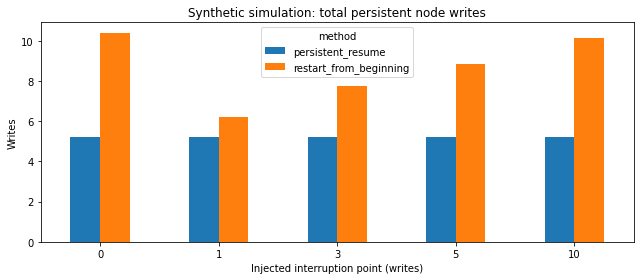

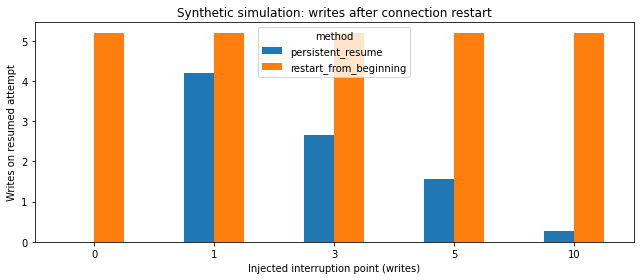

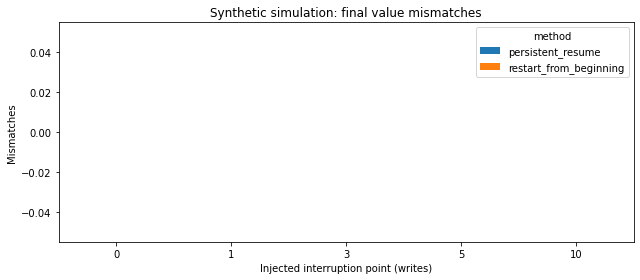

In [6]:
summary_df = results_df.groupby(["crash_after_writes", "method"]).agg(
    mean_first_attempt_writes=("first_attempt_writes", "mean"),
    mean_second_attempt_writes=("second_attempt_writes", "mean"),
    mean_total_writes=("total_writes", "mean"),
    completion_rate=("verified", "mean"),
    mean_value_mismatches=("value_mismatches", "mean")
).reset_index()
display(summary_df)

for metric, title, ylabel in [
    ("mean_total_writes", "Synthetic simulation: total persistent node writes", "Writes"),
    ("mean_second_attempt_writes", "Synthetic simulation: writes after connection restart", "Writes on resumed attempt"),
    ("mean_value_mismatches", "Synthetic simulation: final value mismatches", "Mismatches")
]:
    pivot = summary_df.pivot(index="crash_after_writes", columns="method", values=metric)
    ax = pivot.plot(kind="bar", figsize=(9, 4))
    ax.set_title(title)
    ax.set_xlabel("Injected interruption point (writes)")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

# A completed transaction should remain verified after a separate connection reads it.
sample_tx = "persistent_resume-0-1"
assert verify_transaction(DB_PATH, sample_tx)["verified"]
print("Independent read-back verification passed for sample transaction.")

## 7. Export reproducibility artifacts

In [7]:
results_df.to_csv("trustsr_lab07_persistent_recovery_trials.csv", index=False)
summary_df.to_csv("trustsr_lab07_persistent_recovery_summary.csv", index=False)

# Export per-node journal/state for one representative transaction.
con = connect(DB_PATH)
try:
    sample_nodes_df = pd.read_sql_query(
        "SELECT s.txid, s.node, s.trusted_value, s.current_value, j.status AS journal_status "
        "FROM snapshots s LEFT JOIN journal j ON s.txid=j.txid AND s.node=j.node "
        "WHERE s.txid=? ORDER BY s.node", con, params=("persistent_resume-0-1",)
    )
finally:
    con.close()
sample_nodes_df.to_csv("trustsr_lab07_sample_transaction_audit.csv", index=False)

for name in [
    "trustsr_lab07_persistent_recovery_trials.csv",
    "trustsr_lab07_persistent_recovery_summary.csv",
    "trustsr_lab07_sample_transaction_audit.csv"
]:
    print("Created:", name)
print("SQLite database:", DB_PATH, "| bytes:", DB_PATH.stat().st_size)
print("Evidence classification: local SQLite-backed synthetic prototype.")

Created: trustsr_lab07_persistent_recovery_trials.csv
Created: trustsr_lab07_persistent_recovery_summary.csv
Created: trustsr_lab07_sample_transaction_audit.csv
SQLite database: trustsr_lab07.sqlite3 | bytes: 5603328
Evidence classification: local SQLite-backed synthetic prototype.


## 8. Interpretation and limitations

### What this lab tests
- Recovery state and per-node journal entries persist across SQLite connection close/reopen.
- A simulated interrupted transaction can resume using persisted pending/done entries.
- State update and journal update occur within the same SQLite transaction in this implementation.
- Final verification reads the database through a separate connection.

### What this lab does not prove
- Survival of actual power loss, kernel panic, disk failure, filesystem corruption, or storage hardware that violates durability guarantees.
- Correctness under concurrent writers, multi-process races, malicious database modification, or external side effects.
- Cryptographic snapshot authenticity or trustworthiness of the selected snapshot.
- Production-grade crash consistency or real-world TRUSTSR effectiveness.

### Publication wording
“We implemented a local SQLite-backed synthetic recovery prototype. We injected interruptions between per-node database transactions, reopened database connections, resumed recovery from persisted journal entries, and measured write counts and final state consistency. The experiment does not establish resilience to hardware failure or production security.”

### Lab 07 completion checklist
1. Run all cells in a fresh Colab runtime.
2. Confirm all assertions pass.
3. Inspect the three plots and three CSV exports.
4. Download the SQLite database if you need to inspect the schema and persisted journal.
5. Upload the executed notebook/PDF for review before Lab 08.